In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import tf_keras

In [2]:
class RockPaperScissors:
    """Rock-Paper-Scissors classifier using a Teachable Machine Keras model."""

    def __init__(self, model_path='keras_model.h5', labels_path='labels.txt'):
        self.model = tf_keras.models.load_model(model_path, compile=False)
        with open(labels_path, 'r') as f:
            # each line looks like "0 Rock"
            self.class_names = [line.strip().split(' ', 1)[1] for line in f if line.strip()]

    def preprocess(self, image_path):
        image = Image.open(image_path).convert('RGB')
        image = ImageOps.fit(image, (224, 224), Image.Resampling.LANCZOS)
        x = np.asarray(image, dtype=np.float32)
        x = (x / 127.5) - 1
        return image, x.reshape(1, 224, 224, 3)

    def classify(self, image_path):
        image, x = self.preprocess(image_path)
        prediction = self.model.predict(x, verbose=0)[0]
        index = int(np.argmax(prediction))
        return image, self.class_names[index], float(prediction[index])

In [3]:
rps = RockPaperScissors('keras_model.h5', 'labels.txt')
print('Classes:', rps.class_names)
rps.model.summary()

Classes: ['Rock', 'Paper', 'Scissors']
Model: "sequential_4"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 sequential_1 (Sequential)   (None, 1280)              410208    


 sequential_3 (Sequential)   (None, 3)                 128400    


Total params: 538608 (2.05 MB)


Trainable params: 524528 (2.00 MB)


Non-trainable params: 14080 (55.00 KB)


_________________________________________________________________


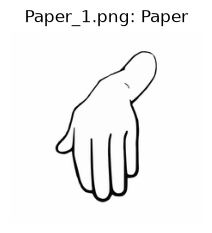

Success: Image Paper_1.png is classified as Paper (confidence 92.36%).


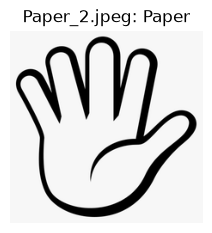

Success: Image Paper_2.jpeg is classified as Paper (confidence 87.79%).


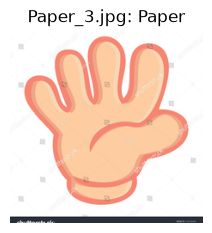

Success: Image Paper_3.jpg is classified as Paper (confidence 98.79%).


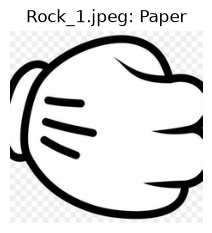

Fail: Image Rock_1.jpeg is classified as Paper (confidence 87.71%).


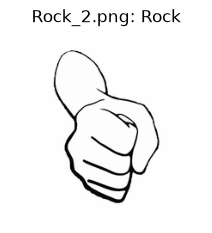

Success: Image Rock_2.png is classified as Rock (confidence 64.65%).


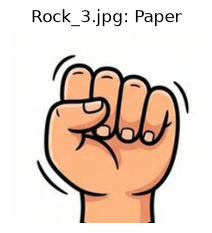

Fail: Image Rock_3.jpg is classified as Paper (confidence 67.59%).


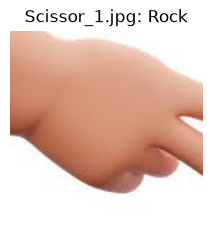

Fail: Image Scissor_1.jpg is classified as Rock (confidence 99.83%).


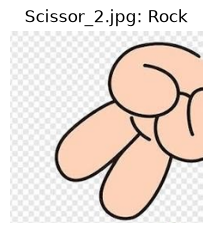

Fail: Image Scissor_2.jpg is classified as Rock (confidence 98.86%).


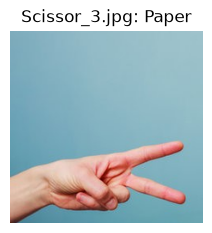

Fail: Image Scissor_3.jpg is classified as Paper (confidence 82.45%).


In [4]:
image_dir = 'Rock_Paper_Scissor'
n_correct = 0
files = sorted(os.listdir(image_dir))

for file_name in files:
    image, label, confidence = rps.classify(os.path.join(image_dir, file_name))
    expected = file_name.split('_')[0]

    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(image)
    plt.title(f'{file_name}: {label}')
    plt.axis('off')
    plt.show()

    correct = expected.lower().rstrip('s') == label.lower().rstrip('s')
    n_correct += correct
    status = 'Success' if correct else 'Fail'
    print(f'{status}: Image {file_name} is classified as {label} (confidence {confidence:.2%}).')

In [5]:
print(f'Accuracy: {n_correct}/{len(files)} = {n_correct / len(files):.2%}')

Accuracy: 4/9 = 44.44%
